# New Dataset Experiment

In [33]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [34]:
df = pd.read_csv("sobar-72.csv")

## 1. Dataset Analysis
### Display basic information about the dataset (rows, columns, data types):

In [35]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes) 

print("\nFirst 5 rows:")
display(df.head())

print("\nSummary statistics:")
display(df.describe())

print("Duplicates:", df.duplicated().sum())

Dataset shape: (72, 20)

Data types:
behavior_sexualRisk           int64
behavior_eating               int64
behavior_personalHygine       int64
intention_aggregation         int64
intention_commitment          int64
attitude_consistency          int64
attitude_spontaneity          int64
norm_significantPerson        int64
norm_fulfillment              int64
perception_vulnerability      int64
perception_severity           int64
motivation_strength           int64
motivation_willingness        int64
socialSupport_emotionality    int64
socialSupport_appreciation    int64
socialSupport_instrumental    int64
empowerment_knowledge         int64
empowerment_abilities         int64
empowerment_desires           int64
ca_cervix                     int64
dtype: object

First 5 rows:


,behavior_sexualRisk,behavior_eating,behavior_personalHygine,intention_aggregation,intention_commitment,attitude_consistency,attitude_spontaneity,norm_significantPerson,norm_fulfillment,perception_vulnerability,perception_severity,motivation_strength,motivation_willingness,socialSupport_emotionality,socialSupport_appreciation,socialSupport_instrumental,empowerment_knowledge,empowerment_abilities,empowerment_desires,ca_cervix
0,10,13,12,4,7,9,10,1,8,7,3,14,8,5,7,12,12,11,8,1
1,10,11,11,10,14,7,7,5,5,4,2,15,13,7,6,5,5,4,4,1
2,10,15,3,2,14,8,10,1,4,7,2,7,3,3,6,11,3,3,15,1
3,10,11,10,10,15,7,7,1,5,4,2,15,13,7,4,4,4,4,4,1
4,8,11,7,8,10,7,8,1,5,3,2,15,5,3,6,12,5,4,7,1



Summary statistics:


,behavior_sexualRisk,behavior_eating,behavior_personalHygine,intention_aggregation,intention_commitment,attitude_consistency,attitude_spontaneity,norm_significantPerson,norm_fulfillment,perception_vulnerability,perception_severity,motivation_strength,motivation_willingness,socialSupport_emotionality,socialSupport_appreciation,socialSupport_instrumental,empowerment_knowledge,empowerment_abilities,empowerment_desires,ca_cervix
count,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000
mean,9.666667,12.791667,11.083333,7.902778,13.347222,7.180556,8.611111,3.125000,8.486111,8.513889,5.388889,12.652778,9.694444,8.097222,6.166667,10.375000,10.541667,9.319444,10.277778,0.291667
std,1.186782,2.361293,3.033847,2.738148,2.374511,1.522844,1.515698,1.845722,4.907577,4.275686,3.400727,3.207209,4.130406,4.243171,2.897303,4.316485,4.366768,4.181874,4.482273,0.457719
min,2.000000,3.000000,3.000000,2.000000,6.000000,2.000000,4.000000,1.000000,3.000000,3.000000,2.000000,3.000000,3.000000,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,0.000000
25%,10.000000,11.000000,9.000000,6.000000,11.000000,6.000000,8.000000,1.000000,3.000000,5.000000,2.000000,11.000000,7.000000,3.000000,3.750000,6.750000,7.000000,5.000000,6.750000,0.000000
50%,10.000000,13.000000,11.000000,10.000000,15.000000,7.000000,9.000000,3.000000,7.000000,8.000000,4.000000,14.000000,11.000000,9.000000,6.500000,12.000000,12.000000,10.000000,11.000000,0.000000
75%,10.000000,15.000000,14.000000,10.000000,15.000000,8.000000,10.000000,5.000000,14.000000,13.000000,9.000000,15.000000,13.000000,11.250000,9.000000,14.250000,15.000000,13.000000,15.000000,1.000000
max,10.000000,15.000000,15.000000,10.000000,15.000000,10.000000,10.000000,5.000000,15.000000,15.000000,10.000000,15.000000,15.000000,15.000000,10.000000,15.000000,15.000000,15.000000,15.000000,1.000000


Duplicates: 0


### Checking for missing values in each column:

In [36]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": (missing / len(df)) * 100
})

display(missing_df)

,Missing Values,Percentage
behavior_sexualRisk,0,0.0
behavior_eating,0,0.0
behavior_personalHygine,0,0.0
intention_aggregation,0,0.0
intention_commitment,0,0.0
attitude_consistency,0,0.0
attitude_spontaneity,0,0.0
norm_significantPerson,0,0.0
norm_fulfillment,0,0.0
perception_vulnerability,0,0.0


### Distribution of Target Variable:

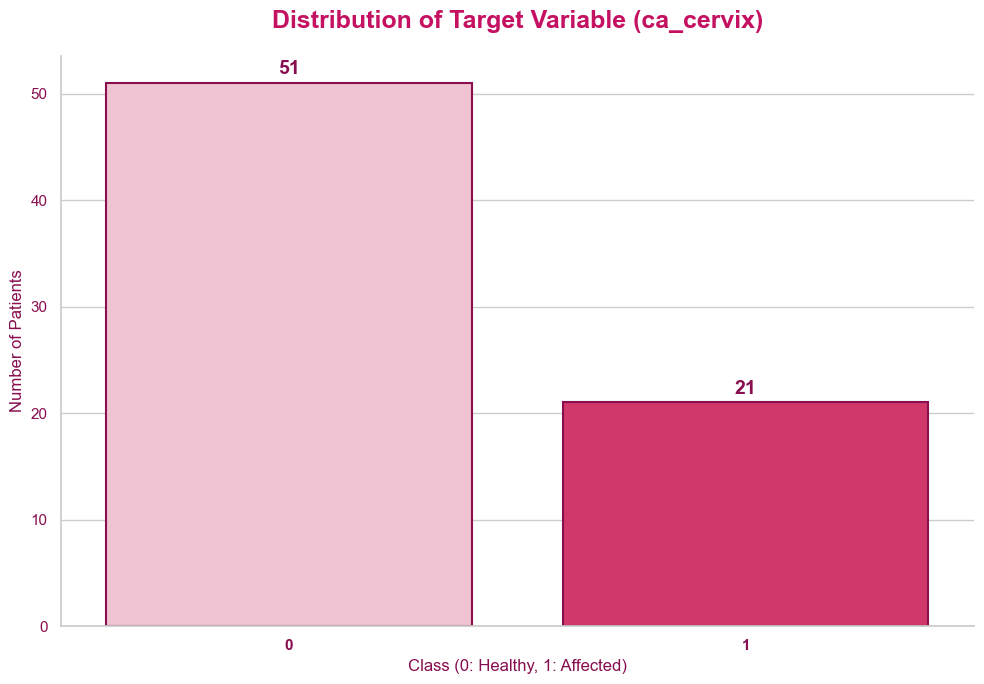

In [37]:
# --- Target Variable Distribution Analysis ---
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 7))
pink_palette = ["#f8bbd0", "#e91e63"]

ax = sns.countplot(
    x=df["ca_cervix"], 
    palette=pink_palette,
    edgecolor="#880e4f",
    linewidth=1.5,
    hue=df["ca_cervix"], 
    legend=False
)

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}', 
        (p.get_x() + p.get_width() / 2., p.get_height()), 
        ha='center', va='center', 
        fontsize=14, 
        color='#880e4f', 
        fontweight='bold',
        xytext=(0, 10), 
        textcoords='offset points'
    )

plt.title("Distribution of Target Variable (ca_cervix)", fontsize=18, color="#c51162", fontweight='bold', pad=20)
plt.xlabel("Class (0: Healthy, 1: Affected)", fontsize=12, color="#880e4f")
plt.ylabel("Number of Patients", fontsize=12, color="#880e4f")

plt.xticks(color="#880e4f", fontweight='bold')
plt.yticks(color="#880e4f")

sns.despine()

plt.tight_layout()
plt.show()

### Summary statistics for numerical features:

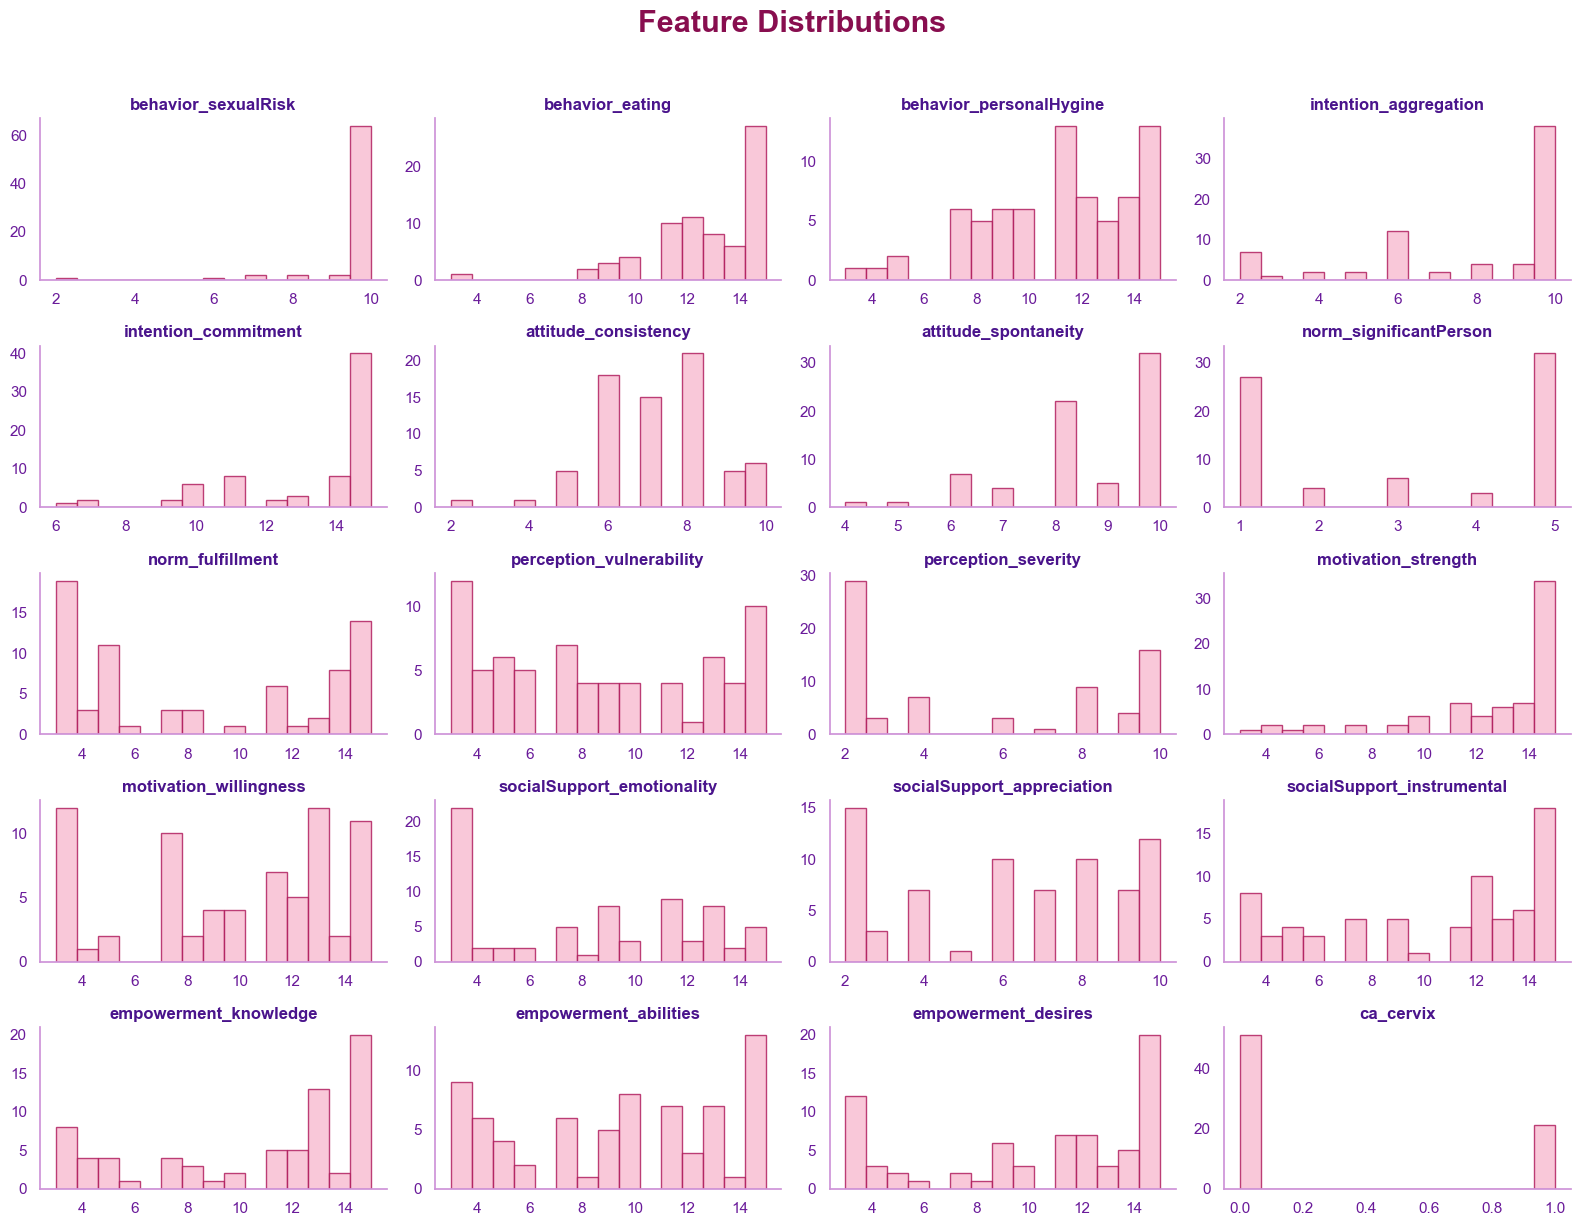

In [38]:
sns.set_theme(style="whitegrid") 

fig = df.hist(
    figsize=(16, 12), 
    bins=15, 
    color="#f8bbd0",       
    edgecolor="#ad1457",   
    grid=False,            
    alpha=0.8              
)

plt.suptitle("Feature Distributions", fontsize=22, color="#880e4f", fontweight='bold', y=1.02)

for ax in fig.flatten():
    ax.set_title(ax.get_title(), fontsize=12, color="#4a148c", fontweight='semibold')
    ax.tick_params(axis='both', colors='#6a1b9a') 
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#ce93d8')
    ax.spines['bottom'].set_color('#ce93d8')

plt.tight_layout()
plt.show()

### Plotting the heatmap with annotations for precise correlation values:

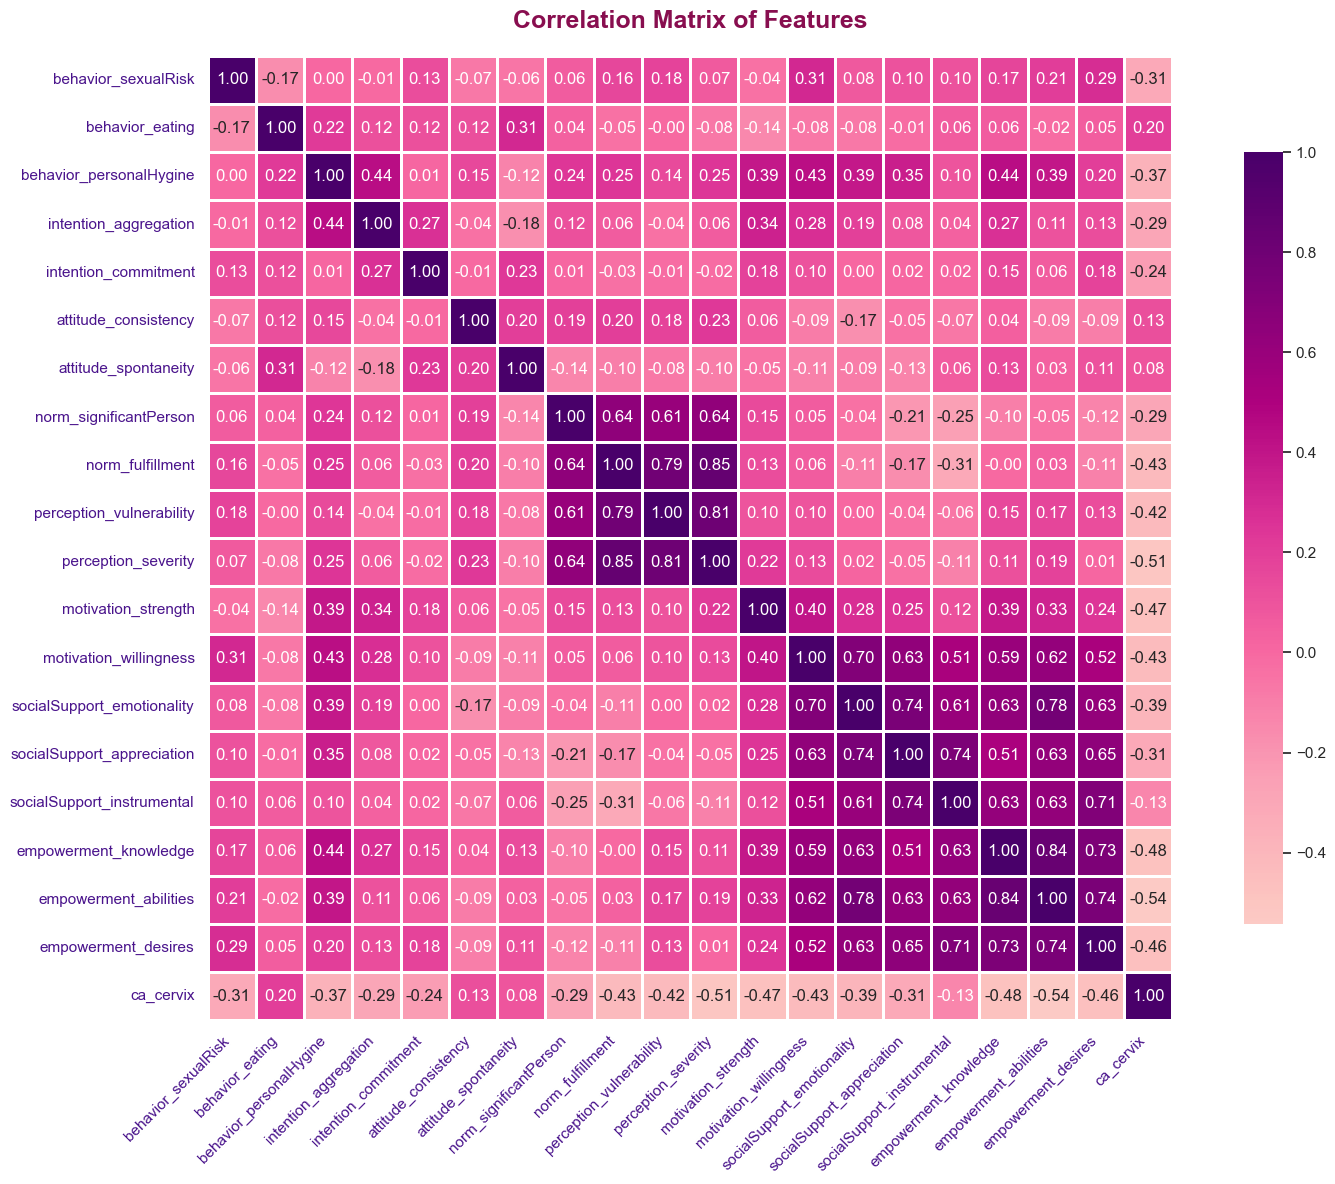

In [40]:
sns.set_theme(style="white")
plt.figure(figsize=(16, 12))
corr = df.corr()
pink_cmap = sns.diverging_palette(300, 350, s=80, l=85, n=20, as_cmap=True)

sns.heatmap(
    corr, 
    annot=True,          
    fmt=".2f",           
    cmap="RdPu",         
    center=0,            
    linewidths=1,        
    linecolor='white',   
    cbar_kws={"shrink": .8}, 
    square=True          
)

plt.title("Correlation Matrix of Features", fontsize=18, color="#880e4f", pad=20, fontweight='bold')
plt.xticks(rotation=45, ha='right', color="#4a148c") 
plt.yticks(color="#4a148c")

plt.tight_layout()
plt.show()

### Identifying the strongest correlations between independent features (Multicollinearity):

In [41]:
corr_matrix = df.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .sort_values(ascending=False)
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

display(high_corr.head(10))

,Feature 1,Feature 2,Correlation
0,norm_fulfillment,perception_severity,0.853534
1,empowerment_knowledge,empowerment_abilities,0.836483
2,perception_vulnerability,perception_severity,0.809409
3,norm_fulfillment,perception_vulnerability,0.792727
4,socialSupport_emotionality,empowerment_abilities,0.779269
5,empowerment_abilities,empowerment_desires,0.743596
6,socialSupport_emotionality,socialSupport_appreciation,0.741054
7,socialSupport_appreciation,socialSupport_instrumental,0.737101
8,empowerment_knowledge,empowerment_desires,0.731940
9,socialSupport_instrumental,empowerment_desires,0.710862


### Correlation with Target Variable:

In [42]:
corr_with_target = df.corr()["ca_cervix"].sort_values(ascending=False)

print(corr_with_target)

ca_cervix                     1.000000
behavior_eating               0.200358
attitude_consistency          0.125447
attitude_spontaneity          0.084590
socialSupport_instrumental   -0.134555
intention_commitment         -0.237040
intention_aggregation        -0.291717
norm_significantPerson       -0.293836
behavior_sexualRisk          -0.311138
socialSupport_appreciation   -0.313307
behavior_personalHygine      -0.372740
socialSupport_emotionality   -0.391905
perception_vulnerability     -0.423109
norm_fulfillment             -0.427674
motivation_willingness       -0.428989
empowerment_desires          -0.458815
motivation_strength          -0.467324
empowerment_knowledge        -0.481814
perception_severity          -0.508217
empowerment_abilities        -0.542360
Name: ca_cervix, dtype: float64


### Using Boxplots to detect potential outliers in the dataset:

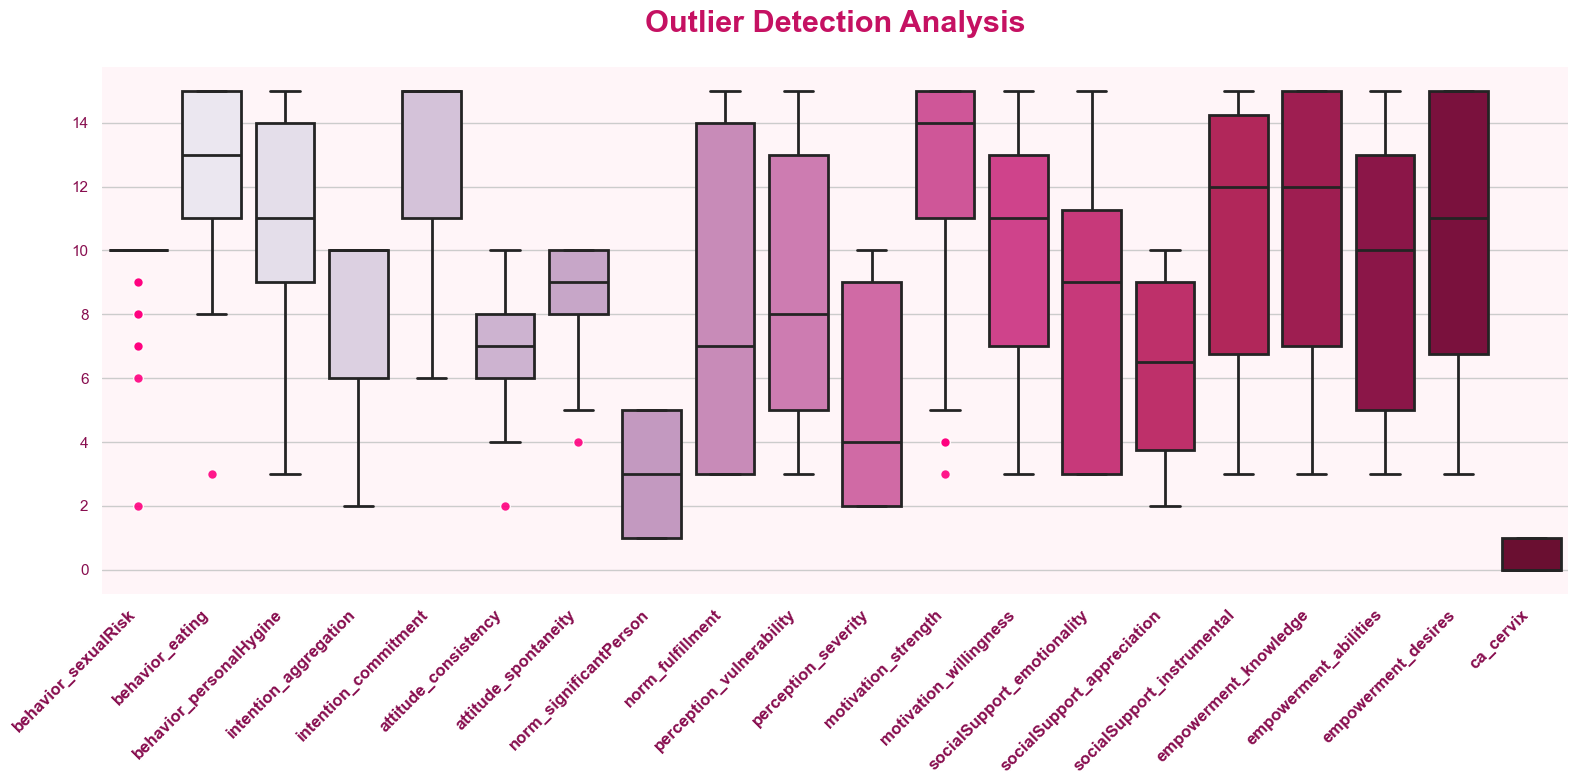

In [43]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(16, 8))

sns.boxplot(
    data=df, 
    palette="PuRd",          
    linewidth=2,             
    fliersize=7,             
    flierprops={
        "marker": "o", 
        "markerfacecolor": "#ff007f", 
        "markeredgecolor": "white", 
        "alpha": 0.9
    } 
)

plt.title("Outlier Detection Analysis", fontsize=22, color="#c51162", fontweight='bold', pad=25)
plt.xticks(rotation=45, ha='right', color="#880e4f", fontsize=12, fontweight='bold')
plt.yticks(color="#880e4f", fontsize=11)
sns.despine(left=True, bottom=True)

plt.gca().set_facecolor('#fff5f8') 

plt.tight_layout()
plt.show()

## 2. Baseline Model

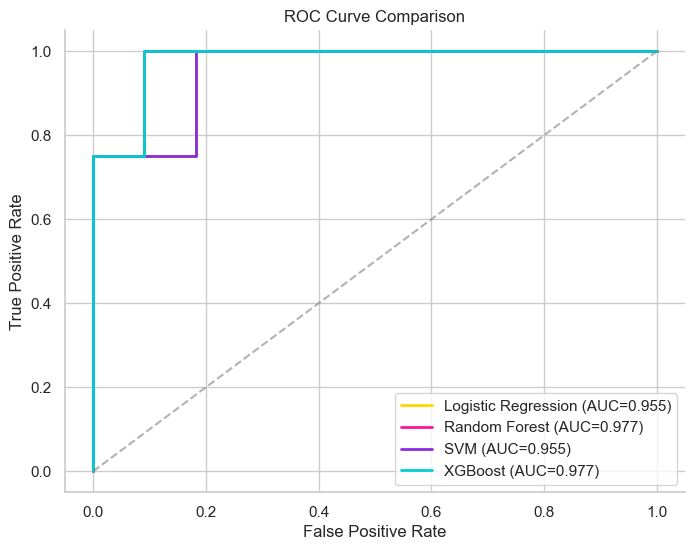

FINAL BASELINE RESULTS:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.866667,0.666667,1.00,0.800000,0.954545
1,Random Forest,0.933333,0.800000,1.00,0.888889,0.977273
3,XGBoost,0.933333,0.800000,1.00,0.888889,0.977273
2,SVM,0.800000,0.600000,0.75,0.666667,0.954545


In [44]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = df.drop("ca_cervix", axis=1)
y = df["ca_cervix"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    "SVM": SVC(
        class_weight='balanced',
        probability=True
    ),

    "XGBoost": XGBClassifier(
        eval_metric='logloss',
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()
    )
}
results = []

line_colors = ["#FFD700", "#FF1493", "#8A2BE2", "#00CED1"]

plt.figure(figsize=(8, 6))
sns.set_style("whitegrid")

for i, (name, model) in enumerate(models.items()):

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "ROC-AUC": auc
    })

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})",
        color=line_colors[i],
        linewidth=2
    )

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', alpha=0.6)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend(loc="lower right")
sns.despine()
plt.show()

df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="Recall", ascending=False)

print("FINAL BASELINE RESULTS:")
display(df_results)

## 3. Model Optimization

In [45]:
X = df.drop("ca_cervix", axis=1)
y = df["ca_cervix"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [46]:
# --- Experimentation Pipeline: Training & Evaluation ---

def run_experiment(X_train, X_test, y_train, y_test, model, param_grid, use_smote=False):
    """
    Function to automate model training using a Pipeline, 
    GridSearchCV for hyperparameter tuning, and performance evaluation.
    """
    
    # 1. Pipeline steps: Scaler is essential for distance-based models like SVM or Logistic Regression
    steps = [
        ("scaler", StandardScaler())
    ]

    # 2. Add SMOTE only if requested (Synthetic Minority Over-sampling Technique)
    if use_smote:
        from imblearn.over_sampling import SMOTE
        steps.append(("smote", SMOTE(random_state=42)))

    # 3. Add the classification model
    steps.append(("model", model))

    from imblearn.pipeline import Pipeline # Note: Using imblearn Pipeline for SMOTE compatibility
    pipeline = Pipeline(steps)

    # 4. Hyperparameter tuning using GridSearchCV with 5-fold cross-validation
    # Focus metric: Recall (Sensitivity) - critical for medical diagnostics
    grid = GridSearchCV(
        pipeline,
        param_grid,
        scoring="recall",
        cv=5,
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    # 5. Extract the best performing model
    best_model = grid.best_estimator_

    # 6. Model Evaluation
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    return {
        "Best Params": grid.best_params_,
        "Model Object": best_model,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

# --- Define Models and Hyperparameters ---

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        {"model__C": [0.1, 1, 10]}
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42, class_weight='balanced'),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 5, 10]
        }
    ),

    "SVM": (
        SVC(probability=True, class_weight='balanced', random_state=42),
        {
            "model__C": [0.1, 1, 10],
            "model__kernel": ["linear", "rbf"]
        }
    ),

    "XGBoost": (
        XGBClassifier(
            eval_metric='logloss',
            random_state=42,
            scale_pos_weight=(y == 0).sum() / (y == 1).sum()
        ),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 5, 10]
        }
    )
}

# --- Running the Experiments Loop ---

results = []

for name, (model, param_grid) in models.items():
    
    # Experiment A: With Class Balancing (SMOTE)
    print(f"Running Experiment: {name} (WITH SMOTE)")
    res_smote = run_experiment(X_train, X_test, y_train, y_test, model, param_grid, use_smote=True)
    res_smote.update({"Model": name, "SMOTE": "Yes"})
    results.append(res_smote)

    # Experiment B: Without SMOTE (Baseline)
    print(f"Running Experiment: {name} (WITHOUT SMOTE)")
    res_no_smote = run_experiment(X_train, X_test, y_train, y_test, model, param_grid, use_smote=False)
    res_no_smote.update({"Model": name, "SMOTE": "No"})
    results.append(res_no_smote)

# --- Compile and Display Results ---

df_results = pd.DataFrame(results)
# Sort by Recall then Precision to find the safest medical model
df_results = df_results.sort_values(by=["Recall", "Precision"], ascending=False)

print("\n--- Final Model Performance Comparison ---")
display(df_results.drop(columns=["Model Object", "Best Params"]))

Running Experiment: Logistic Regression (WITH SMOTE)
Running Experiment: Logistic Regression (WITHOUT SMOTE)
Running Experiment: Random Forest (WITH SMOTE)
Running Experiment: Random Forest (WITHOUT SMOTE)
Running Experiment: SVM (WITH SMOTE)
Running Experiment: SVM (WITHOUT SMOTE)
Running Experiment: XGBoost (WITH SMOTE)
Running Experiment: XGBoost (WITHOUT SMOTE)

--- Final Model Performance Comparison ---


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Model,SMOTE
3,0.933333,0.800000,1.00,0.888889,0.977273,Random Forest,No
7,0.933333,0.800000,1.00,0.888889,0.977273,XGBoost,No
2,0.866667,0.666667,1.00,0.800000,0.977273,Random Forest,Yes
6,0.866667,0.666667,1.00,0.800000,0.977273,XGBoost,Yes
0,0.733333,0.500000,1.00,0.666667,0.931818,Logistic Regression,Yes
1,0.666667,0.444444,1.00,0.615385,0.909091,Logistic Regression,No
4,0.800000,0.600000,0.75,0.666667,0.954545,SVM,Yes
5,0.800000,0.600000,0.75,0.666667,0.954545,SVM,No


## 4. Performance Validation and Results Interpretation
## Confusion Matrices for Top Performing Models:

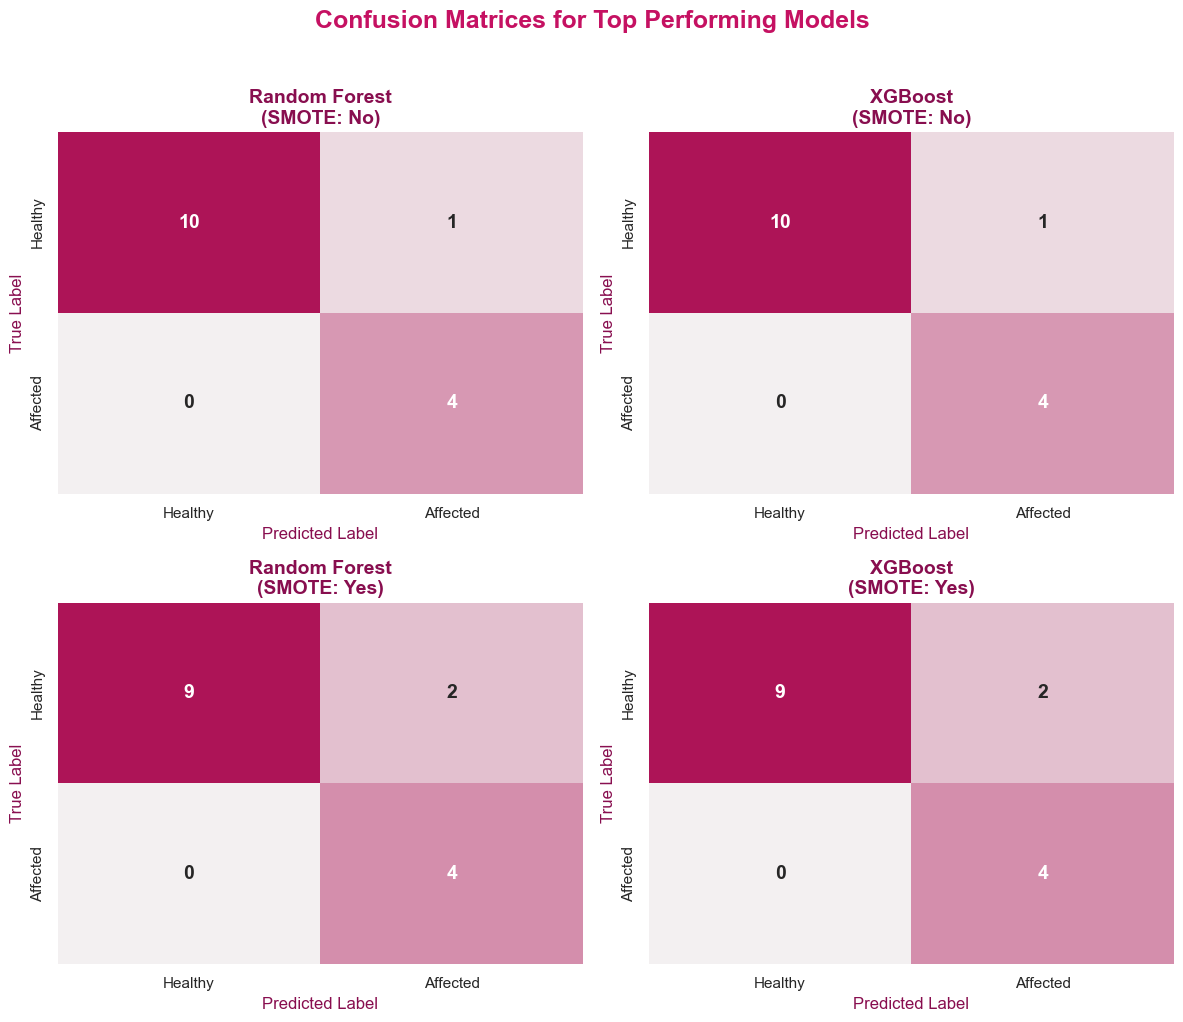

In [47]:
top_models = df_results.head(4)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

pink_cmap = sns.light_palette("#ad1457", as_cmap=True)

for i, (idx, row) in enumerate(top_models.iterrows()):
    ax = axes[i]
    model = row["Model Object"]
    model_name = row["Model"]
    smote_status = row["SMOTE"]
    
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap=pink_cmap, cbar=False,
                annot_kws={"size": 14, "fontweight": "bold"})
    
    ax.set_title(f"{model_name}\n(SMOTE: {smote_status})", fontsize=14, color="#880e4f", fontweight='bold')
    ax.set_xlabel("Predicted Label", color="#880e4f")
    ax.set_ylabel("True Label", color="#880e4f")
    ax.set_xticklabels(['Healthy', 'Affected'])
    ax.set_yticklabels(['Healthy', 'Affected'])

plt.suptitle("Confusion Matrices for Top Performing Models", fontsize=18, color="#c51162", fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Data Splitting Validation: Train vs Test Set Proportions:

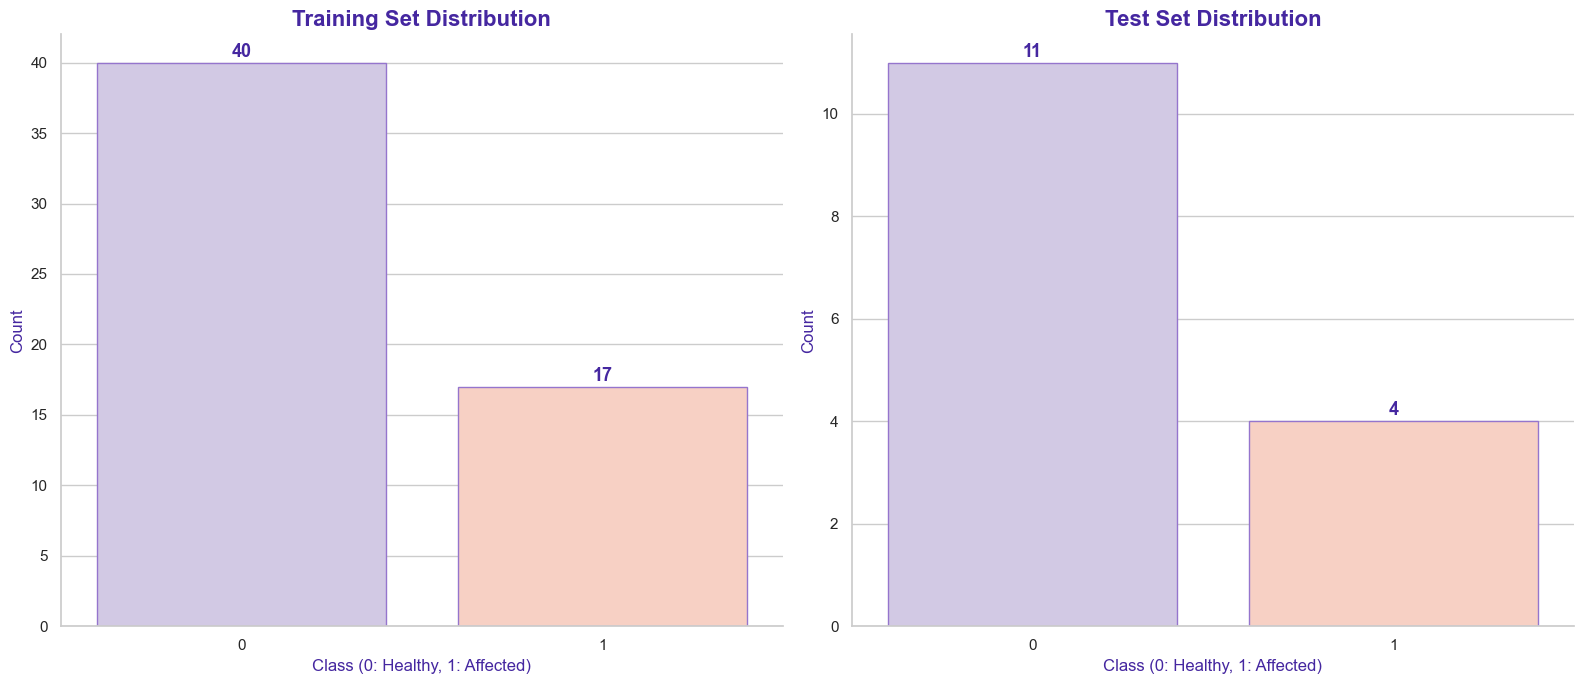

In [48]:
# --- Training and Testing Set Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.set_theme(style="whitegrid")

lavender = "#d1c4e9" 
peach = "#ffccbc"  
custom_palette = [lavender, peach]

sns.countplot(
    x=y_train, 
    ax=axes[0], 
    palette=custom_palette, 
    edgecolor="#9575cd", 
    hue=y_train, 
    legend=False
)
axes[0].set_title("Training Set Distribution", fontsize=16, color="#4527a0", fontweight='bold')
axes[0].set_xlabel("Class (0: Healthy, 1: Affected)", color="#4527a0")
axes[0].set_ylabel("Count", color="#4527a0")

sns.countplot(
    x=y_test, 
    ax=axes[1], 
    palette=custom_palette, 
    edgecolor="#9575cd", 
    hue=y_test, 
    legend=False
)
axes[1].set_title("Test Set Distribution", fontsize=16, color="#4527a0", fontweight='bold')
axes[1].set_xlabel("Class (0: Healthy, 1: Affected)", color="#4527a0")
axes[1].set_ylabel("Count", color="#4527a0")

for ax in axes:
    for p in ax.patches:
        ax.annotate(
            f'{int(p.get_height())}', 
            (p.get_x() + p.get_width() / 2., p.get_height()), 
            ha='center', va='center', 
            fontsize=13, color='#4527a0', fontweight='bold', 
            xytext=(0, 8), textcoords='offset points'
        )
        
sns.despine()

plt.tight_layout()
plt.show()

## Comprehensive Model Validation: Comparative Cross-Validation:

In [49]:
from sklearn.model_selection import cross_val_score

cv_results = []

for row in results:
    
    model_name = row["Model"]
    smote_status = row["SMOTE"]
    model_pipeline = row["Model Object"]
    
    scores = cross_val_score(
        model_pipeline,
        X,
        y,
        cv=5,
        scoring="recall",
        n_jobs=-1
    )
    
    cv_results.append({
        "Model": model_name,
        "SMOTE": smote_status,
        "Mean Recall": scores.mean(),
        "Std Recall": scores.std()
    })

df_cv = pd.DataFrame(cv_results)
df_cv = df_cv.sort_values(by="Mean Recall", ascending=False)

display(df_cv)

,Model,SMOTE,Mean Recall,Std Recall
1,Logistic Regression,No,0.85,0.122474
0,Logistic Regression,Yes,0.81,0.096954
2,Random Forest,Yes,0.80,0.187083
4,SVM,Yes,0.80,0.187083
5,SVM,No,0.80,0.187083
6,XGBoost,Yes,0.80,0.244949
3,Random Forest,No,0.76,0.159374
7,XGBoost,No,0.71,0.190788


### Model Explainability with SHAP Values

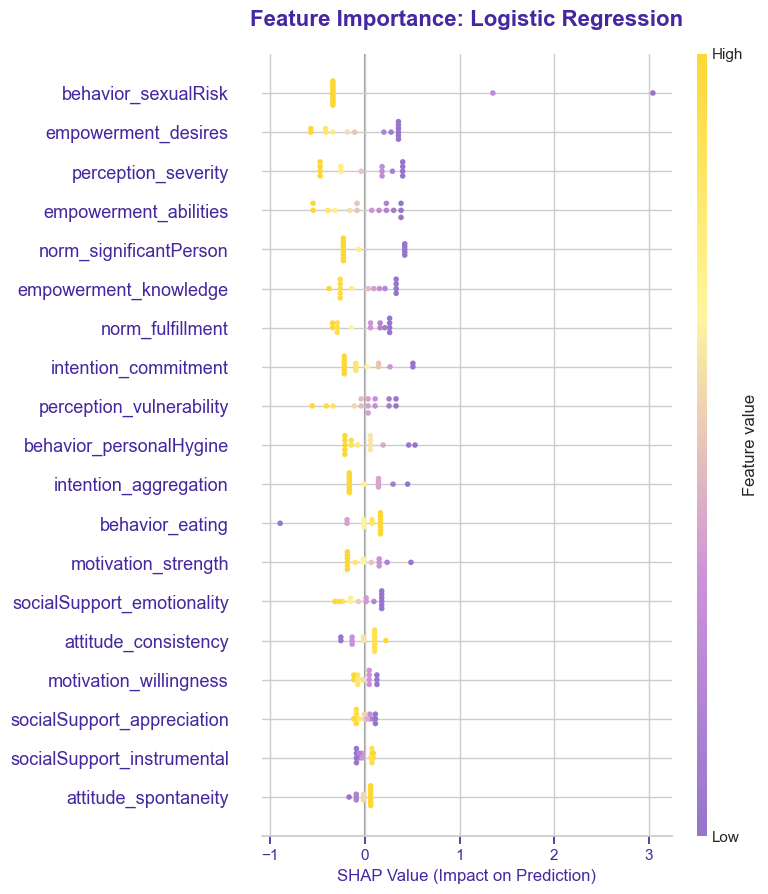

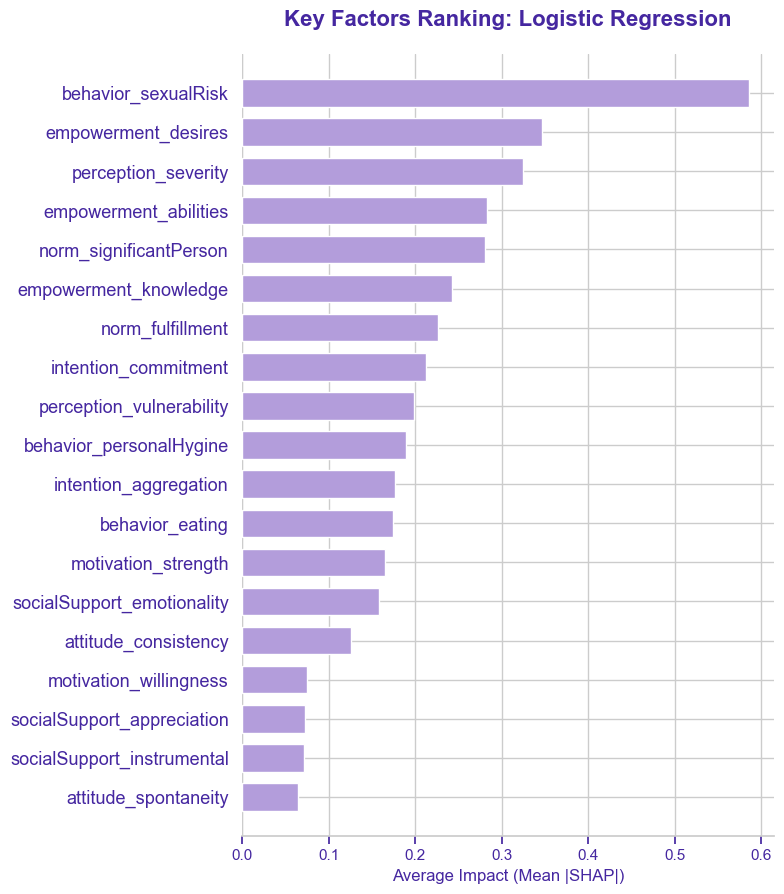

In [50]:
import shap
from matplotlib.colors import LinearSegmentedColormap

best_row = df_cv.sort_values(
    by=["Mean Recall", "Std Recall"],
    ascending=[False, True]
).iloc[0]

best_model_name = best_row["Model"]
best_smote = best_row["SMOTE"]

best_pipeline = df_results[
    (df_results["Model"] == best_model_name) & 
    (df_results["SMOTE"] == best_smote)
]["Model Object"].values[0]

model_obj = best_pipeline.named_steps["model"]
X_processed = best_pipeline.named_steps["scaler"].transform(X_test)

if isinstance(model_obj, LogisticRegression):
    explainer = shap.LinearExplainer(model_obj, X_processed)
    shap_values = explainer.shap_values(X_processed)
elif isinstance(model_obj, (RandomForestClassifier, XGBClassifier)):
    explainer = shap.TreeExplainer(model_obj)
    shap_values = explainer.shap_values(X_processed)
    if isinstance(shap_values, list) and len(shap_values) > 1:
        shap_values = shap_values[1]
else:
    explainer = shap.Explainer(model_obj, X_processed)
    shap_values = explainer(X_processed)

colors = ["#9575cd", "#ce93d8", "#fff59d", "#fdd835"] 
lavender_yellow_cmap = LinearSegmentedColormap.from_list("lavender_yellow", colors)

plt.figure(figsize=(10, 6))
plt.title(f"Feature Importance: {best_model_name}", fontsize=16, color="#4527a0", fontweight='bold', pad=20)

shap.summary_plot(
    shap_values, 
    X_processed, 
    feature_names=X.columns, 
    show=False,
    plot_type="dot"
)

for fc in plt.gcf().get_children():
    for v in fc.get_children():
        if hasattr(v, 'set_cmap'):
            v.set_cmap(lavender_yellow_cmap)

plt.gcf().axes[0].set_xlabel("SHAP Value (Impact on Prediction)", color="#4527a0", fontsize=12)
plt.gca().tick_params(axis='both', colors='#4527a0')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.title(f"Key Factors Ranking: {best_model_name}", fontsize=16, color="#4527a0", fontweight='bold', pad=20)

shap.summary_plot(
    shap_values, 
    X_processed, 
    feature_names=X.columns, 
    plot_type="bar", 
    show=False,
    color="#b39ddb" 
)

plt.gcf().axes[0].set_xlabel("Average Impact (Mean |SHAP|)", color="#4527a0", fontsize=12)
plt.gca().tick_params(axis='both', colors='#4527a0')
plt.tight_layout()
plt.show()